# Customer Churn Prediction (IBM Telco dataset)

**Goal:** predict whether a telecom customer will leave (`Churn` = Yes/No).

This is **supervised learning** (specifically *classification*): every customer has input
**features** (X: contract type, tenure, charges, ...) and a known **target** (y: did they churn?).
The model learns the link between X and y from past customers.

**Workflow:** load data -> split -> baseline -> compare 3 models -> regularization ->
tune Random Forest -> choose final model (validation only) -> test once -> extras.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
if "get_ipython" not in globals():      # plain script: save figures without opening windows
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, RocCurveDisplay,
                             ConfusionMatrixDisplay, r2_score)

warnings.filterwarnings("ignore", message=".*non-interactive.*")

RANDOM_STATE = 42  # fixed seed -> same results every run

# Paths are built from this file's location, so it works no matter where you launch it from.
ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

## Step 1: Load and understand the data
Things to check before modelling: size, data types, missing values, duplicates, class balance.

Shape: (7043, 21)
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object 

Missing values:
 TotalCharges    11
dtype: int64 

Duplicate customerIDs: 0
Removed 22 exact duplicate rows (identical features and target) -> 7021 rows left

Class balance (proportion):
 Churn
0    0.736
1    0.264
Name: proportion, dtype: float64

Numeric features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dep

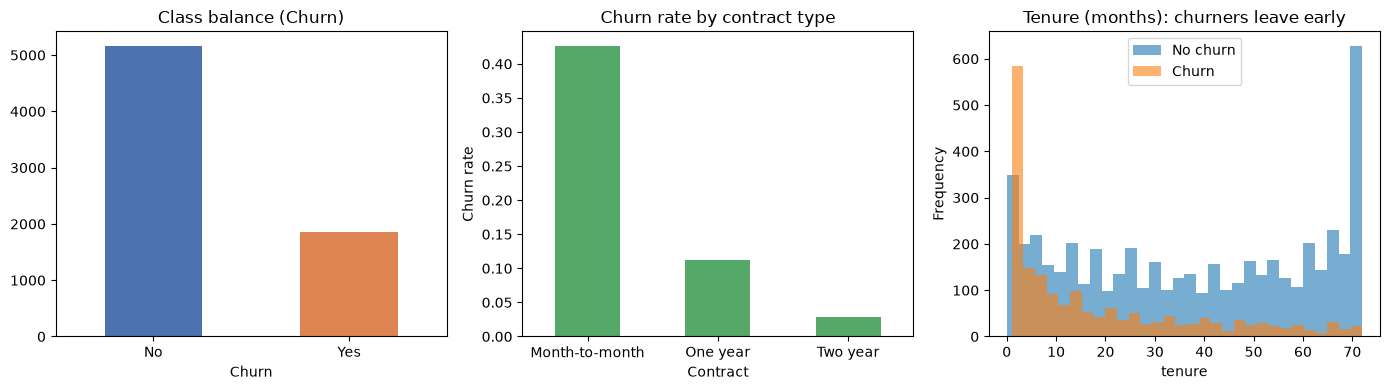

In [2]:
df = pd.read_csv(ROOT / "data" / "telco.csv")
print("Shape:", df.shape)
print(df.dtypes, "\n")

# TotalCharges is stored as text because new customers (tenure 0) have a blank value.
# to_numeric turns those blanks into NaN, which our pipeline will fill in later.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0], "\n")

# Target: Yes -> 1, No -> 0
df["Churn"] = (df["Churn"] == "Yes").astype(int)

# Duplicate checks (part of the leakage checklist)
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())

# customerID is only a label, not a real predictor, so we drop it.
df = df.drop(columns=["customerID"])

# Rows that are identical in every feature AND the target would otherwise land in different splits
# (e.g. one copy in train, one in test), making the test score slightly optimistic.
# So we remove them BEFORE splitting.
n_dupes = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_dupes} exact duplicate rows (identical features and target) -> {len(df)} rows left")
print("\nClass balance (proportion):\n", df["Churn"].value_counts(normalize=True).round(3))

# SeniorCitizen is stored as 0/1 but it is a category, so treat it as one.
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# Features (X) and target (y)
X = df.drop(columns=["Churn"])
y = df["Churn"]

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_cols = [c for c in X.columns if c not in numeric_cols]
print("\nNumeric features:", numeric_cols)
print("Categorical features:", categorical_cols)

# Three simple EDA charts
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
df["Churn"].value_counts().rename({0: "No", 1: "Yes"}).plot.bar(ax=ax[0], color=["#4c72b0", "#dd8452"], rot=0)
ax[0].set_title("Class balance (Churn)")
df.groupby("Contract")["Churn"].mean().plot.bar(ax=ax[1], color="#55a868", rot=0)
ax[1].set_title("Churn rate by contract type"); ax[1].set_ylabel("Churn rate")
df.groupby("Churn")["tenure"].plot.hist(ax=ax[2], alpha=0.6, bins=30, legend=True)
ax[2].legend(["No churn", "Churn"]); ax[2].set_title("Tenure (months): churners leave early")
ax[2].set_xlabel("tenure")
plt.tight_layout()
plt.savefig(FIGURES / "01_eda.png", dpi=120)
plt.show()
plt.close()

## Step 2: Split the data (stratified 70 / 15 / 15)
- **Train (70%)** - the model learns from this.
- **Validation (15%)** - we compare models, tune settings and pick the threshold here.
- **Test (15%)** - a final exam, looked at **once** at the very end.

We split **before** any preprocessing so nothing from validation/test leaks into training.
`stratify` keeps the same churn percentage in all three parts.

In [3]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

for name, part in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:10s} rows={len(part):5d}  churn rate={part.mean():.3f}")

Train      rows= 4914  churn rate=0.265
Validation rows= 1053  churn rate=0.264
Test       rows= 1054  churn rate=0.265


## Step 3: Preprocessing + baseline (Logistic Regression)
Preprocessing lives **inside a Pipeline**, so it is fitted only on the training data
(and re-fitted inside every cross-validation fold). That is how we prevent leakage.

- **Imputer** fills missing values (median for numbers, most common value for categories).
- **StandardScaler** puts numbers on the same scale (mean 0, std 1); important for Logistic Regression.
- **OneHotEncoder** turns text categories into 0/1 columns the model can use.

`class_weight="balanced"` tells the model churners are rarer, so missing one costs more.
We judge models by precision, recall, F1 and ROC-AUC (accuracy is misleading when only ~27% churn).

In [4]:
def make_pipeline(model):
    numeric_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    prep = ColumnTransformer([
        ("num", numeric_steps, numeric_cols),
        ("cat", categorical_steps, categorical_cols),
    ])
    return Pipeline([("prep", prep), ("model", model)])


def get_scores(pipe, X_part, y_part, threshold=0.5):
    """Precision, recall, F1 and ROC-AUC for a fitted pipeline."""
    proba = pipe.predict_proba(X_part)[:, 1]          # predicted probability of churn
    pred = (proba >= threshold).astype(int)
    return {
        "precision": precision_score(y_part, pred),
        "recall": recall_score(y_part, pred),
        "f1": f1_score(y_part, pred),
        "roc_auc": roc_auc_score(y_part, proba),
    }


# Reference point: always guessing "no churn" is already ~73% accurate but finds zero churners.
print(f"Accuracy of always predicting 'No churn' (validation): {1 - y_val.mean():.3f}")

baseline = make_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced"))
baseline.fit(X_train, y_train)
print("\nBaseline (Logistic Regression) on validation:")
print({k: round(v, 3) for k, v in get_scores(baseline, X_val, y_val).items()})

Accuracy of always predicting 'No churn' (validation): 0.736

Baseline (Logistic Regression) on validation:
{'precision': 0.52, 'recall': 0.791, 'f1': 0.628, 'roc_auc': 0.843}


## Step 4: Compare three models (same split, same preprocessing, same metrics)
We also compare **train F1 vs validation F1**. A big gap = **overfitting**: the model memorised
the training data instead of learning a pattern that carries over to new customers.

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
}

fitted = {}   # keep the fitted pipelines so we can reuse them in Step 6
rows = []
for name, model in models.items():
    pipe = make_pipeline(model).fit(X_train, y_train)
    fitted[name] = pipe
    tr = get_scores(pipe, X_train, y_train)
    va = get_scores(pipe, X_val, y_val)
    rows.append({"model": name, "train_f1": tr["f1"], "val_f1": va["f1"], "f1_gap": tr["f1"] - va["f1"],
                 "val_precision": va["precision"], "val_recall": va["recall"], "val_roc_auc": va["roc_auc"]})

print(pd.DataFrame(rows).round(3).to_string(index=False))

              model  train_f1  val_f1  f1_gap  val_precision  val_recall  val_roc_auc
Logistic Regression     0.634   0.628   0.007          0.520       0.791        0.843
      Decision Tree     0.996   0.495   0.501          0.504       0.486        0.657
      Random Forest     0.987   0.588   0.399          0.558       0.622        0.820


## Step 5a: Overfitting and regularization curves
- **Logistic Regression:** `C` is the inverse of regularization strength. Small C = stronger penalty = simpler model.
- **Decision Tree:** larger `max_depth` = more complex model (limiting depth is its form of regularization).

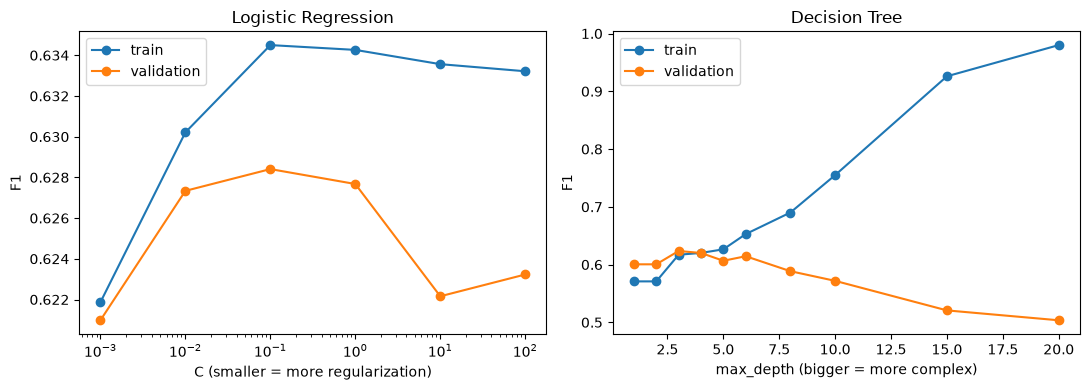

Logistic Regression validation F1 by C: {0.001: 0.621, 0.01: 0.627, 0.1: 0.628, 1: 0.628, 10: 0.622, 100: 0.623}
Tree: best max_depth on validation = 3 (val F1 0.624); unlimited tree train F1 = 0.996


In [6]:
c_values = [0.001, 0.01, 0.1, 1, 10, 100]
lr_train, lr_val = [], []
for c in c_values:
    p = make_pipeline(LogisticRegression(C=c, max_iter=1000, class_weight="balanced")).fit(X_train, y_train)
    lr_train.append(get_scores(p, X_train, y_train)["f1"])
    lr_val.append(get_scores(p, X_val, y_val)["f1"])

depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]
dt_train, dt_val = [], []
for d in depths:
    p = make_pipeline(DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE,
                                             class_weight="balanced")).fit(X_train, y_train)
    dt_train.append(get_scores(p, X_train, y_train)["f1"])
    dt_val.append(get_scores(p, X_val, y_val)["f1"])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(c_values, lr_train, "o-", label="train")
ax[0].plot(c_values, lr_val, "o-", label="validation")
ax[0].set_xscale("log"); ax[0].set_xlabel("C (smaller = more regularization)")
ax[0].set_ylabel("F1"); ax[0].set_title("Logistic Regression"); ax[0].legend()
ax[1].plot(depths, dt_train, "o-", label="train")
ax[1].plot(depths, dt_val, "o-", label="validation")
ax[1].set_xlabel("max_depth (bigger = more complex)")
ax[1].set_ylabel("F1"); ax[1].set_title("Decision Tree"); ax[1].legend()
plt.tight_layout()
plt.savefig(FIGURES / "02_overfitting_curves.png", dpi=120)
plt.show()
plt.close()

best_depth = depths[int(np.argmax(dt_val))]
print("Logistic Regression validation F1 by C:", {c: round(float(f), 3) for c, f in zip(c_values, lr_val)})
print("Tree: best max_depth on validation =", best_depth,
      f"(val F1 {max(dt_val):.3f}); unlimited tree train F1 = {rows[1]['train_f1']:.3f}")

## Step 5b: Tune Random Forest with stratified cross-validation (training data only)
- **Metric chosen before tuning:** F1.
- **Cross-validation:** the training set is cut into 5 folds; each fold takes a turn as a mini
  validation set. Preprocessing is re-fitted inside each fold because it is in the Pipeline.
- **Small grid** (2 x 3 x 3 = 18 settings) so it runs quickly and is easy to explain.

The validation set is not used for tuning, so it stays an honest check of the tuned model.

In [7]:
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_leaf": [1, 5, 10],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rf_pipe = make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"))

search = GridSearchCV(rf_pipe, param_grid, scoring="f1", cv=cv, n_jobs=-1)
search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)

# Compare default vs tuned fold by fold, using the grid search's own cross-validation results.
# The default Random Forest settings (100 trees, no depth limit, min_samples_leaf=1) are one of the
# 18 grid cells, so both scores come from the same folds. We do NOT re-score the winner on those folds
# again: they were used to pick it, so that would be an over-optimistic, non-independent estimate.
# These are TUNING scores. The honest comparison is the validation set below.
results = pd.DataFrame(search.cv_results_)
fold_cols = [f"split{i}_test_score" for i in range(5)]
default_row = results[(results["param_model__n_estimators"] == 100)
                      & (results["param_model__max_depth"].isna())
                      & (results["param_model__min_samples_leaf"] == 1)].iloc[0]
tuned_row = results.loc[search.best_index_]
default_cv_mean = float(default_row["mean_test_score"])
tuned_cv_mean = float(search.best_score_)
print("Default RF tuning-CV F1 per fold:", default_row[fold_cols].astype(float).round(3).values,
      "mean", round(default_cv_mean, 3))
print("Tuned   RF tuning-CV F1 per fold:", tuned_row[fold_cols].astype(float).round(3).values,
      "mean", round(tuned_cv_mean, 3))

best_rf = search.best_estimator_            # already refit on the full training set
fitted["Random Forest (tuned)"] = best_rf
tr = get_scores(best_rf, X_train, y_train)
va = get_scores(best_rf, X_val, y_val)
rows.append({"model": "Random Forest (tuned)", "train_f1": tr["f1"], "val_f1": va["f1"],
             "f1_gap": tr["f1"] - va["f1"], "val_precision": va["precision"],
             "val_recall": va["recall"], "val_roc_auc": va["roc_auc"]})

# Final model comparison table, saved as CSV
comparison = pd.DataFrame(rows).round(3)
comparison["tuning_cv_f1"] = [np.nan, np.nan, default_cv_mean, tuned_cv_mean]  # only RF was grid-searched
comparison = comparison.round(3)
comparison.to_csv(ROOT / "reports" / "model_comparison.csv", index=False)
print("\nModel comparison (validation set):")
print(comparison.to_string(index=False))

Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
Default RF tuning-CV F1 per fold: [0.645 0.551 0.597 0.593 0.573] mean 0.592
Tuned   RF tuning-CV F1 per fold: [0.668 0.614 0.666 0.63  0.586] mean 0.633

Model comparison (validation set):
                model  train_f1  val_f1  f1_gap  val_precision  val_recall  val_roc_auc  tuning_cv_f1
  Logistic Regression     0.634   0.628   0.007          0.520       0.791        0.843           NaN
        Decision Tree     0.996   0.495   0.501          0.504       0.486        0.657           NaN
        Random Forest     0.987   0.588   0.399          0.558       0.622        0.820         0.592
Random Forest (tuned)     0.721   0.626   0.095          0.533       0.759        0.846         0.633


## Step 6: Choose the final model and threshold using VALIDATION data only
Rule fixed in advance: the model with the best **validation F1** wins.
F1 balances precision (don't waste retention offers) and recall (don't miss people who leave);
ROC-AUC is the supporting metric because it shows how well customers are ranked at *any* threshold.

The model outputs a churn probability. We normally call it "churn" above 0.5, but we check
other thresholds on the validation set and keep the best one.

In [8]:
final_name = comparison.loc[comparison["val_f1"].idxmax(), "model"]
final_model = fitted[final_name]
print("Selected model:", final_name)

val_proba = final_model.predict_proba(X_val)[:, 1]
thresholds = np.arange(0.2, 0.81, 0.05)
f1_by_threshold = [f1_score(y_val, (val_proba >= t).astype(int)) for t in thresholds]
best_threshold = round(float(thresholds[int(np.argmax(f1_by_threshold))]), 2)
print("Validation F1 by threshold:", {round(float(t), 2): round(float(f), 3) for t, f in zip(thresholds, f1_by_threshold)})
print("Chosen threshold:", best_threshold)

Selected model: Logistic Regression


Validation F1 by threshold: {0.2: 0.559, 0.25: 0.579, 0.3: 0.593, 0.35: 0.603, 0.4: 0.606, 0.45: 0.614, 0.5: 0.628, 0.55: 0.617, 0.6: 0.617, 0.65: 0.607, 0.7: 0.59, 0.75: 0.577, 0.8: 0.469}
Chosen threshold: 0.5


## Step 7: Final evaluation on the untouched TEST set (used only once)
Every decision (model, settings, threshold) is already made. The test score estimates how the
model would do on brand-new customers.

TEST scores: {'precision': 0.506, 'recall': 0.814, 'f1': 0.624, 'roc_auc': 0.852}

Confusion matrix (rows = actual, columns = predicted):
 [[553 222]
 [ 52 227]]

               precision    recall  f1-score   support

    No churn       0.91      0.71      0.80       775
       Churn       0.51      0.81      0.62       279

    accuracy                           0.74      1054
   macro avg       0.71      0.76      0.71      1054
weighted avg       0.81      0.74      0.75      1054



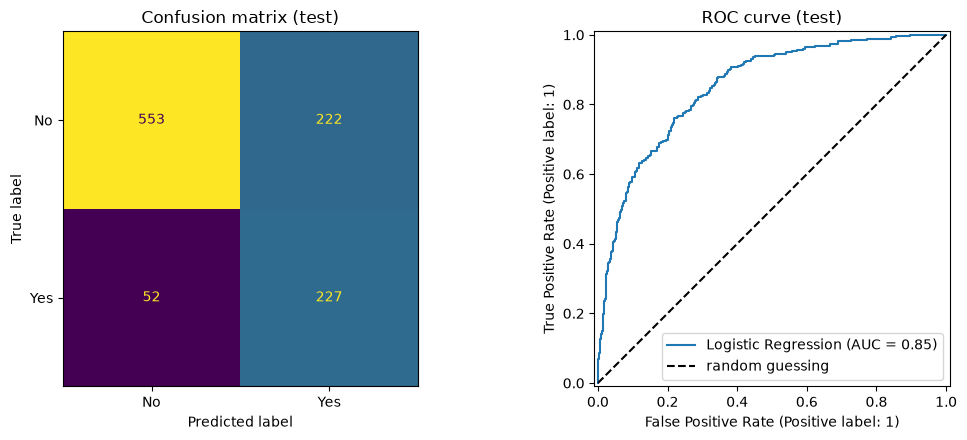

In [9]:
test_scores = get_scores(final_model, X_test, y_test, threshold=best_threshold)
print("TEST scores:", {k: round(v, 3) for k, v in test_scores.items()})

test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)
print("\nConfusion matrix (rows = actual, columns = predicted):\n", confusion_matrix(y_test, test_pred))
print("\n", classification_report(y_test, test_pred, target_names=["No churn", "Churn"]))

pd.DataFrame([{"model": final_name, "threshold": best_threshold,
               **{f"test_{k}": round(v, 3) for k, v in test_scores.items()}}]
             ).to_csv(ROOT / "reports" / "final_test_results.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["No", "Yes"], ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (test)")
RocCurveDisplay.from_predictions(y_test, test_proba, ax=ax[1], name=final_name)
ax[1].plot([0, 1], [0, 1], "k--", label="random guessing")
ax[1].set_title("ROC curve (test)"); ax[1].legend()
plt.tight_layout()
plt.savefig(FIGURES / "03_final_evaluation.png", dpi=120)
plt.show()
plt.close()

## Step 8: What drives churn? (interpretability)
Logistic Regression coefficients: positive = raises churn probability, negative = lowers it.
Random Forest importance: how much a feature helps the trees make splits.
(These describe patterns in the data, not proof of cause.)

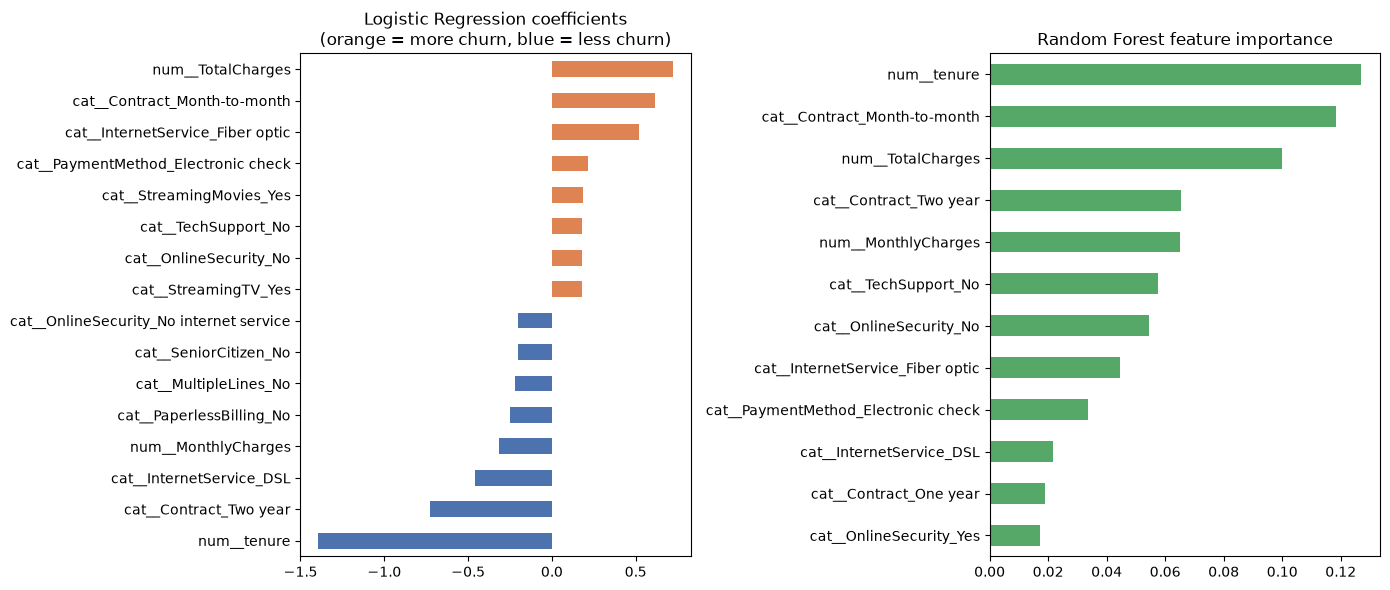

Top 5 features (Random Forest):
 num__tenure                     0.127
cat__Contract_Month-to-month    0.118
num__TotalCharges               0.100
cat__Contract_Two year          0.065
num__MonthlyCharges             0.065
dtype: float64


In [10]:
feature_names = baseline.named_steps["prep"].get_feature_names_out()

coefs = pd.Series(baseline.named_steps["model"].coef_[0], index=feature_names).sort_values()
top_lr = pd.concat([coefs.head(8), coefs.tail(8)])

rf_imp = pd.Series(best_rf.named_steps["model"].feature_importances_, index=feature_names)
top_rf = rf_imp.sort_values().tail(12)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
top_lr.plot.barh(ax=ax[0], color=["#4c72b0" if v < 0 else "#dd8452" for v in top_lr])
ax[0].set_title("Logistic Regression coefficients\n(orange = more churn, blue = less churn)")
top_rf.plot.barh(ax=ax[1], color="#55a868")
ax[1].set_title("Random Forest feature importance")
plt.tight_layout()
plt.savefig(FIGURES / "04_feature_effects.png", dpi=120)
plt.show()
plt.close()
print("Top 5 features (Random Forest):\n", top_rf.sort_values(ascending=False).head(5).round(3))

## Leakage checklist
- [x] Data is split **before** any preprocessing is fitted (Step 2).
- [x] Imputer, scaler and encoder are inside the Pipeline, so they learn only from training data (Step 3).
- [x] Cross-validation re-fits preprocessing inside each fold (Step 5b).
- [x] `customerID` is dropped; no feature is recorded after the customer leaves (checked column meanings).
- [x] Test data is not used for model choice, tuning or the threshold (Steps 6-7).
- [x] Duplicates inspected: no repeated IDs; exact duplicate rows (identical features and target) are removed **before** splitting so a copy cannot sit in train while its twin sits in test (Step 1).
- [x] The tuning cross-validation score is reported as a *tuning* score only; the validation set is used for the honest model comparison (Step 5b).
- Note: the optional KMeans and linear-regression demos use all rows and are not part of the leakage-free churn evaluation.

## Optional extra A: Linear regression (predict a NUMBER, not a class)
Linear regression fits a straight-line formula `y = b0 + b1*x1 + b2*x2 + ...` to predict a
continuous value. Logistic regression is the same idea, but squeezes the result into a 0-1
probability so it can be used for classification. Here we predict `MonthlyCharges`;
the metric is R^2 (1.0 = perfect), not F1. This is a separate mini-experiment, not part of the churn result.
Note: the high R^2 does not mean this is a hard or useful problem. Monthly price is mostly
determined by which services a customer has, so it is an easy thing to predict.

In [11]:
reg_X = df[["tenure", "SeniorCitizen", "InternetService", "PhoneService", "StreamingTV"]]
reg_y = df["MonthlyCharges"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(reg_X, reg_y, test_size=0.2, random_state=RANDOM_STATE)
reg_prep = ColumnTransformer([
    ("num", StandardScaler(), ["tenure"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["SeniorCitizen", "InternetService", "PhoneService", "StreamingTV"]),
])
reg = Pipeline([("prep", reg_prep), ("model", LinearRegression())]).fit(Xr_tr, yr_tr)
r2 = r2_score(yr_te, reg.predict(Xr_te))
print("Linear regression R^2 on held-out data:", round(r2, 3))

Linear regression R^2 on held-out data: 0.949


## Optional extra B: Unsupervised learning (KMeans clustering)
Here there is **no target**: KMeans simply groups similar customers by tenure and monthly charges.
We look at churn only *after* clustering, to describe the groups. This is separate from the
classification task above. It scales and clusters ALL rows, so it is a descriptive demo only
and is NOT part of the leakage-free churn evaluation.

         customers  avg_tenure  avg_monthly  churn_rate
cluster                                                
0             2280       57.96        89.02        0.16
1             2127       29.55        26.50        0.12
2             2614       12.61        74.98        0.47


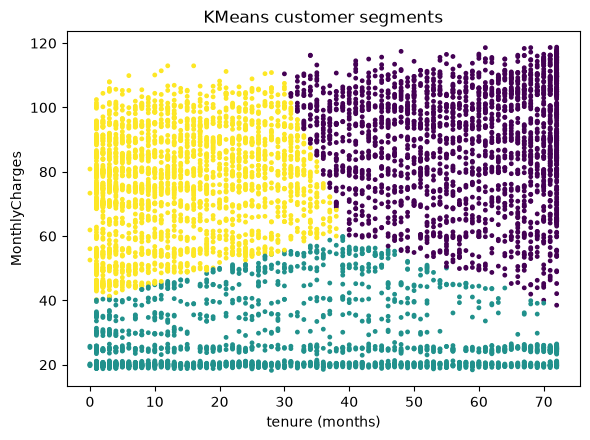


Done. See reports/ for the tables and figures.


In [12]:
cluster_data = StandardScaler().fit_transform(df[["tenure", "MonthlyCharges"]])
km = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit(cluster_data)
df["cluster"] = km.labels_
summary = df.groupby("cluster").agg(customers=("Churn", "size"),
                                    avg_tenure=("tenure", "mean"),
                                    avg_monthly=("MonthlyCharges", "mean"),
                                    churn_rate=("Churn", "mean")).round(2)
print(summary)

plt.figure(figsize=(6, 4.5))
plt.scatter(df["tenure"], df["MonthlyCharges"], c=df["cluster"], s=6, cmap="viridis")
plt.xlabel("tenure (months)"); plt.ylabel("MonthlyCharges"); plt.title("KMeans customer segments")
plt.tight_layout()
plt.savefig(FIGURES / "05_clusters.png", dpi=120)
plt.show()
plt.close()

print("\nDone. See reports/ for the tables and figures.")